# t-SNE 与 PCA 的区别

| 对比维度 | PCA（主成分分析） | t-SNE |
| :--- | :--- | :--- |
| 方法类型 | 线性降维 | 非线性降维 |
| 核心目标 | 最大化数据在低维空间中的方差 | 保留高维空间中点对点的局部相似性 |
| 全局 vs 局部 | 适合保留全局结构 | 强调局部结构 |
| 速度和效率 | 快速，计算复杂度低 | 较慢，计算复杂度高 |
| 结果解释 | 降维后的主成分具有明确的线性意义 | 降维结果仅用于可视化和聚类分析 |
| 应用场景 | 特征提取、压缩维度 | 数据可视化、模式发现、聚类分析 |

### 主成分分析 PCA
经典的无监督线性降维算法，PCA不关心类别，只关心数据在哪几个方向上的波动（方差）最大
然后将数据投影到主要方向上，实现降维
PCA认为，特征的“信息量”不取决于其平均值，而是取决于其方差。方差越大说明数据在该特征的区分度越高。
如方差为0，说明该特征毫无信息量，可以直接丢弃。

**核心流程**
- 标准化：同K-Means和逻辑回归，必须进行标准化，否则量纲大的特征会完全覆盖量纲小的特征
- 计算协方差矩阵：对角线上是每个特征的方差，非对角线元素是特征间的协方差（衡量两个随机变量的变化方向是否一致）
- 计算特征值和特征向量：特征值代表主成分的方差大小，特征值越大，说明该方向的信息量越多
- 选择主成分投影：将特征值升序排列，选出K个特征值对于的特征向量，组成投影矩阵W。W与原始1数据相乘，得到降维后的新数据  $X_{new} = X*W$

**如何确认K值**
- 解释方差比，通常累计解释方差比达到90%~95%即可
- 肘部法则，同K-Means


各主成分解释的方差比例: [0.72962445 0.22850762]
累计解释方差比例: 0.9581320720000164


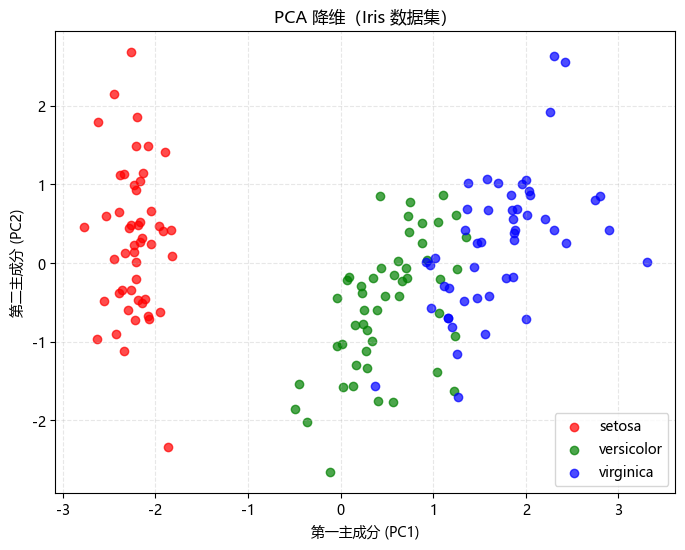


主成分载荷（特征对 PC 的贡献）:
[[ 0.52106591 -0.26934744  0.5804131   0.56485654]
 [ 0.37741762  0.92329566  0.02449161  0.06694199]]


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


# 设置中文字体
plt.rc('font', **{'family': 'Microsoft YaHei, SimHei'})
plt.rcParams['axes.unicode_minus'] = False

# 1. 加载数据
iris = load_iris()
X = iris.data          # 原始特征 (150个样本, 4个特征)
y = iris.target        # 标签 (0,1,2)
target_names = iris.target_names


# 2. 数据标准化（非常重要！PCA 对量纲敏感）
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. 进行 PCA 降维（降到 2 维，方便画图）
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# 4. 查看降维后的主成分解释了多少方差
print("各主成分解释的方差比例:", pca.explained_variance_ratio_)
print("累计解释方差比例:", sum(pca.explained_variance_ratio_))

# 5. 可视化降维结果
plt.figure(figsize=(8, 6))
colors = ['red', 'green', 'blue']
for i, color in enumerate(colors):
    plt.scatter(X_pca[y == i, 0], X_pca[y == i, 1], 
                c=color, label=target_names[i], alpha=0.7)

plt.xlabel('第一主成分 (PC1)')
plt.ylabel('第二主成分 (PC2)')
plt.title('PCA 降维（Iris 数据集）')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()

# 6. （附加）看每个原始特征对主成分的贡献权重
print("\n主成分载荷（特征对 PC 的贡献）:")
print(pca.components_)  # 形状为 (2, 4)，对应 2 个主成分 × 4 个原始特征

### t-SNE
不同于PCA，t-SNE是一种 非线性 的降维方法，且专注于在高维数据中保留点与点之间的局部结构，适合可视化高维复杂数据
如图像、文本、嵌入向量

**核心思想**
通过计算概率分布来衡量高维空间中点与点之间的相似性，并且尝试在低维空间重建概率分布，保留这些相似性

**算法流程**
- 计算高纬空间中的相似性：以每一个数据点$x_i$为中心，使用高斯分布来衡量其他点$x_j$成为其邻居的概率
  $p_{i|j} = \frac{\exp\left(-\|x_i - x_j\|^2 / 2\sigma_i^2\right)}{\sum_{k \neq i} \exp\left(-\|x_i - x_k\|^2 / 2\sigma_i^2\right)}$
- 高维空间中任意两点的联合概率分布为：$p_{ij} = \frac{p_{i|j}+p_{j|i}}{2n}$ n为数据点总数
- 计算低维空间中的相似性：$q_{ij} = \frac{(1 + \|y_i - y_j\|^2)^{-1}}{\sum_{k \neq l} (1 + \|y_k - y_l\|^2)^{-1}}$          $y_i 和 y_j$ 是低维空间中的数据点
- 损失函数（KL散度）:通过最小化高维概率分布P和低维概率分布Q之间的KL散度来优化
    低维空间中的表示$C = \sum_{i≠j}p_{ij}log\frac{p_{ij}}{q_{ij}}$
- 通过梯度下降法优化损失函数


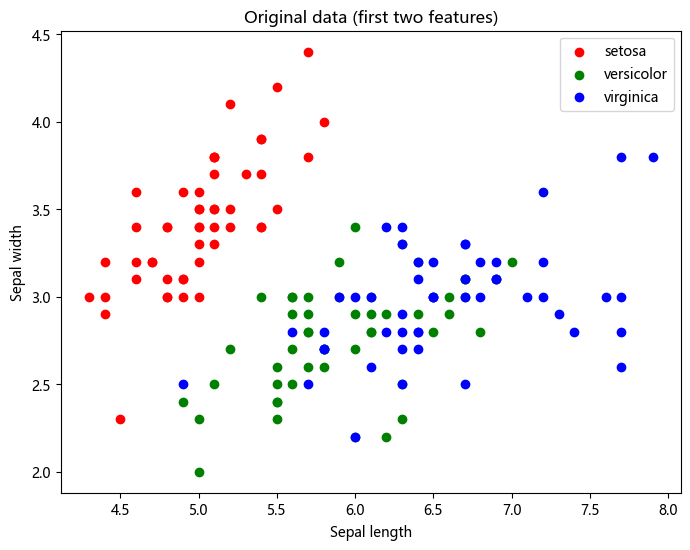

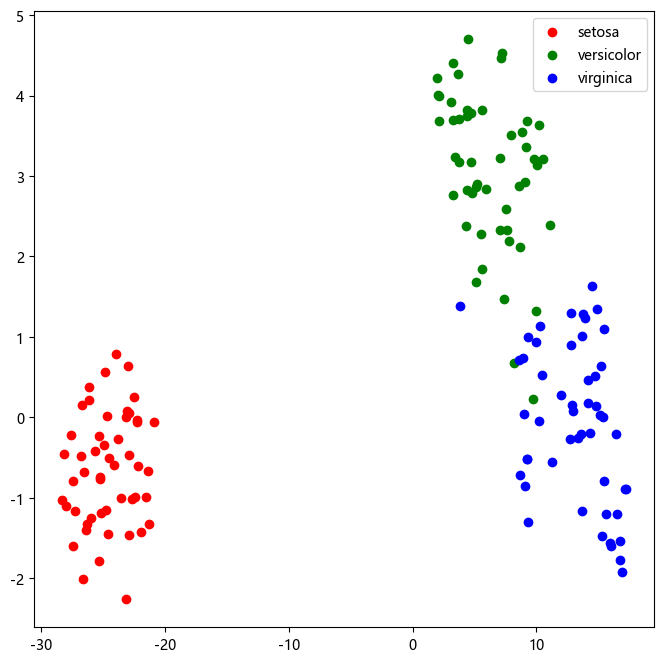

In [8]:

from sklearn.manifold import TSNE
from sklearn.datasets import load_iris
import matplotlib.pyplot as plt

# 加载数据
iris = load_iris()
X = iris.data
y = iris.target

plt.figure(figsize=(8, 6))
for i, color in enumerate(['red', 'green', 'blue']):
    plt.scatter(X[y == i, 0], X[y == i, 1],
                c=color, label=iris.target_names[i])
plt.xlabel('Sepal length')
plt.ylabel('Sepal width')
plt.legend()
plt.title('Original data (first two features)')
plt.show()

# t-SNE 降维
tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X)

# 可视化
plt.figure(figsize=(8, 8))
colors = ['red', 'green', 'blue']
for i in range(len(colors)):
    plt.scatter(X_tsne[y == i, 0], X_tsne[y == i, 1], c=colors[i], label=iris.target_names[i])
plt.legend()
plt.show()